# Demo 1 — QSP và tìm pha
**Người nói 1 · 06:30–09:00 (2 phút 30)**

Ý chính: một chuỗi phép quay một qubit tạo ra đa thức $P(x)$; chọn pha là chọn đa thức.

## Cell 1 — Thiết lập
Toàn bộ hàm nằm trong `src/qsvt_demo.py`, seed cố định.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"

import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qsvt_demo import *
import qsvt_demo

plt.rcParams.update({"font.size": 13, "figure.figsize": (8, 3.6), "axes.grid": True})
reset_rng()
print(f"Qiskit {qiskit.__version__} | numpy {np.__version__} | seed {SEED}")

Qiskit 2.6.2 | numpy 2.5.5 | seed 1234


## Cell 2 — Pha bằng 0 cho đúng Chebyshev $T_d$
$U_\Phi(x)=e^{i\phi_0 Z}\prod_k W(x)e^{i\phi_k Z}$ với mọi $\phi_k=0$ cho $P(x)=\cos(d\arccos x)=T_d(x)$.

T_3: err = 8.2e-16
T_6: err = 1.9e-15
T_9: err = 2.5e-15


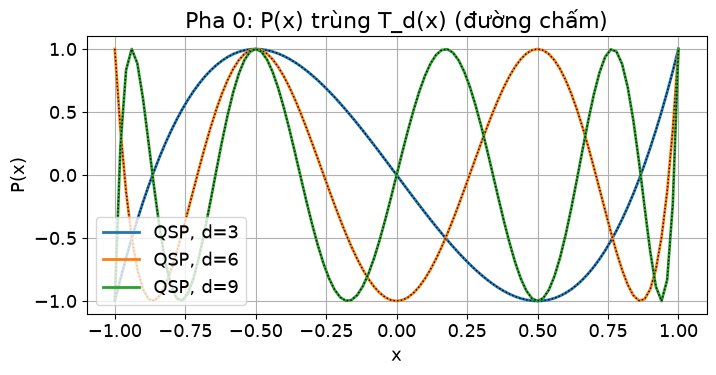

PASS


In [2]:
xs = np.linspace(-1, 1, 101)
fig, ax = plt.subplots()
ok = True
for d in [3, 6, 9]:
    P = np.array([qsp(np.zeros(d + 1), x, "Wx")[0, 0] for x in xs])
    err = np.max(np.abs(P - np.cos(d * np.arccos(xs))))
    ok &= err < 1e-12
    print(f"T_{d}: err = {err:.1e}")
    ax.plot(xs, P.real, lw=2, label=f"QSP, d={d}")
    ax.plot(xs, np.cos(d * np.arccos(xs)), "k:", lw=1)
ax.set_xlabel("x"); ax.set_ylabel("P(x)"); ax.set_title("Pha 0: P(x) trùng T_d(x) (đường chấm)")
ax.legend(loc="lower left"); plt.show()
print(verdict(ok))

## Cell 3 — Quy ước $R_Z$: $e^{i\phi Z}=R_Z(-2\phi)$
Sai dấu ở đây là sai toàn bộ QSP khi chuyển sang mạch.

In [3]:
from qiskit.circuit.library import RZGate
from qiskit.quantum_info import Operator
phi = 0.37
err = np.linalg.norm(Operator(RZGate(-2 * phi)).data - z_phase(phi))
print(f"e^(i phi Z) vs RZ(-2 phi): {err:.1e}", verdict(err < 1e-12))

e^(i phi Z) vs RZ(-2 phi): 0.0e+00 PASS


## Cell 4 — Tìm pha cho $f(x)=0.8\cos(3x)$, bậc $d=10$
BFGS tự viết, 8 lần khởi tạo, khớp $\mathrm{Re}\,P$ trên nút Chebyshev. Tiêu chí E1: sai số đều $<10^{-4}$.

11 pha, sai số đều = 1.97e-06, thời gian 7.3 s
[ 2.7682 -0.8735  2.4688 -1.7626 -1.0122 -2.7199 -2.0631 -1.3153  3.1418
 -1.8328 -0.5977]


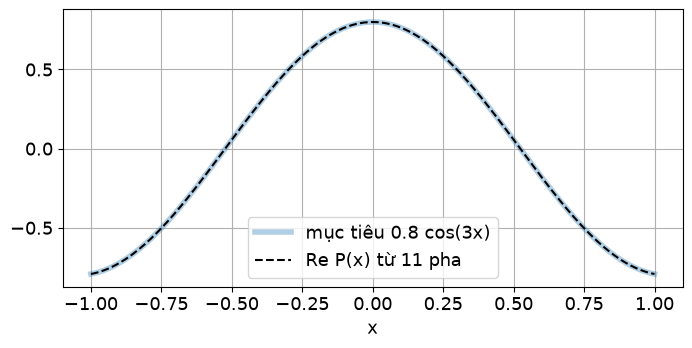

PASS


In [4]:
import time
f1 = lambda x: 0.8 * np.cos(3 * x)
t0 = time.time()
reset_rng()
phis, err = find_phases(f1, 10)
np.save(DATA / "phases_cos3x_d10.npy", phis)
print(f"{len(phis)} pha, sai số đều = {err:.2e}, thời gian {time.time() - t0:.1f} s")
print(np.round(phis, 4))

grid = np.linspace(-1, 1, 401)
ReP = np.array([qsp(phis, x)[0, 0].real for x in grid])
fig, ax = plt.subplots()
ax.plot(grid, f1(grid), lw=4, alpha=0.35, label="mục tiêu 0.8 cos(3x)")
ax.plot(grid, ReP, "k--", lw=1.5, label="Re P(x) từ 11 pha")
ax.set_xlabel("x"); ax.legend(loc="lower center"); plt.show()
print(verdict(err < 1e-4))

## Cell 4b — Dự phòng
Nếu cell 4 chạy quá 20 giây: đọc pha đã lưu và vẽ lại.

In [5]:
phis = np.load(DATA / "phases_cos3x_d10.npy")
grid = np.linspace(-1, 1, 401)
err = np.max(np.abs([qsp(phis, x)[0, 0].real - f1(x) for x in grid]))
print(f"pha đã lưu: sai số đều = {err:.2e}", verdict(err < 1e-4))

pha đã lưu: sai số đều = 1.97e-06 PASS


## Cell 5 — Luôn kiểm tra $\max|f|\le 1$ trước khi tìm pha
QSP chỉ tạo được đa thức bị chặn bởi 1 trên $[-1,1]$.

In [6]:
m = check_bounded(f1)
print(f"max|f| trên lưới 4001 điểm = {m:.3f}", verdict(m <= 1))

max|f| trên lưới 4001 điểm = 0.800 PASS
